<a href="https://colab.research.google.com/github/aghosh92/IEEE_ferroschool_AI_lab_2026/blob/main/notebooks/IEEE_Ferroschool_2026_Notebook01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 1: Learning the Landau landscape

#### Prepared by: Ayana Ghosh
####Contact: ghosha@iitm.ac.in

### Welcome!

This notebook is meant to provide an introduction to the concepts of underfitting/overfitting, generalization, distribution shifts, uncertainty, and physics-informed learning using a known ferroelectric free-energy landscape..

Best opened in Google Colab.

**What we'll do?**

We'll build a Landau toy model, treat it as a *known ground truth*, such that we can see exactly how ML models succeed and fail.

We'll then use that to decide which algorithm and which physical constraints to use on real data.

| | Notebook | Sections | Question it answers |
|---|---|---|---|
| **1** | Physics, data and fitting | 1–3 | What is the physics, what does the data look like, and how do models under- and overfit it? |
| **2** | Shifts and uncertainty | 4–5 | Where do fitted models break (interpolation, extrapolation, hidden-variable OOD), and can their uncertainty be trusted? |
| **3** | Physics-informed models | 6–7 | What does physical knowledge buy us, and how do we choose algorithms and constraints? |


**In this notebook:** (1) the order-parameter equation for and its first-order transition, (2) a dense, noisy synthetic experiment with a plain train/test split, (3) underfitting vs overfitting.

> **Requirements:** numpy, pandas, scipy, scikit-learn, matplotlib. The Landau coefficients here are toy values (Curie constant from Curie–Weiss, T_C and the polarization jump chosen by hand).

Note: A real materials such as BTO also has T→O (~278 K) and O→R (~183 K) transitions that this 1-D model does not contain.

## 1. The physics: a 2-4-6 Landau–Devonshire free energy

For polarization $P$ along $[001]$ (tetragonal BTO), with applied field $E$:

$$F(P,T,E)=a\,(T-T_0)\,P^2+b\,P^4+c\,P^6-E\,P ,\qquad a=\frac{1}{2\varepsilon_0 C_{CW}}>0,\; c>0 .$$

| Symbol | Meaning | Units |
|---|---|---|
| $F$ | free-energy density (minimised) | J m⁻³ |
| $P$ | polarization, the order parameter | C m⁻² |
| $T$, $T_0$ | temperature; Curie–Weiss temperature (paraelectric state loses stability) | K |
| $E$ | applied electric field (set to 0 here) | V m⁻¹ |
| $a$ | coefficient of $P^2$, fixed by $C_{CW}$ | J m C⁻² K⁻¹ |
| $b$ | coefficient of $P^4$; $b<0$ gives a first-order transition | J m⁵ C⁻⁴ |
| $c$ | coefficient of $P^6$; $c>0$ keeps $F$ bounded below | J m⁹ C⁻⁶ |
| $C_{CW}$ | Curie–Weiss constant, from $\varepsilon_r\approx C_{CW}/(T-T_0)$ above $T_C$ (about $10^5$ K for BTO) | K |
| $\varepsilon_0$ | vacuum permittivity, $8.854\times10^{-12}$ | F m⁻¹ |

Only even powers of $P$ appear because the cubic phase is symmetric under $P\to-P$; the field term $-EP$ is what breaks that symmetry. Note that $C_{CW}$ (a measured constant in kelvin) is unrelated to the lowercase sextic coefficient $c$.

* $b>0$ → **second-order** (continuous) transition, $P_s\propto (T_C-T)^{1/2}$.
* $b<0$ → **first-order** transition (BTO): $P_s$ **jumps** at $T_C>T_0$.

At $E=0$ the equilibrium $P_s$ minimises $F$. Writing $x=P^2$, $\alpha=a/c$, $\beta=b/c$, stationarity gives a quadratic with a **closed form**:

$$x_\pm=\frac{-\beta\pm\sqrt{\beta^2-3\alpha (T-T_0)}}{3},\qquad T_C=T_0+\frac{\beta^2}{4\alpha}.$$

Note that $P_s(T)$ at $E=0$ depends only on **three** combinations $(\alpha,\beta,T_0)$ — not on $a$, $b$, $c$ separately. We come back to this *identifiability* issue in notebook 3.

Import libraries

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

In [ ]:
# Set up a clean, reproducible plotting environment and consistent colors.

warnings.filterwarnings("ignore")

rng = np.random.default_rng(7)   # fixed seed: same dataset every run
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10})
COL = dict(train="#1f77b4", test="#2ca02c", model="#d62728")

In [ ]:
# @title Defining functions
#error function
def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

#simulate energy with Landau toy model
def free_energy(P, T, E=0.0):
    return a * (T - T0) * P**2 + b * P**4 + c * P**6 - E * P

#calculating polarization
def Ps_landau(T, alpha, beta, T0):
    # Equilibrium (global-minimum) spontaneous polarization, E=0. Vectorised, closed form.
    T = np.asarray(T, float)
    disc = beta**2 - 3 * alpha * (T - T0)
    x = (-beta + np.sqrt(np.maximum(disc, 0))) / 3
    ferro = (disc >= 0) & (x > 0) & (alpha * (T - T0) + beta * x + x**2 < 0)   # F(x+) < F(0)
    return np.where(ferro, np.sqrt(np.maximum(x, 0)), 0.0)

#polynomial model
def poly_model(d):
    return make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())

def sweep(n, reps, degrees=range(1, 16)):
    # median train / CV / test RMSE over `reps` random training subsets of size n
    rows = []
    for r in range(reps):
        sub = rng.choice(len(T_tr), n, replace=False)
        T, y = T_tr[sub], y_tr[sub]
        for d in degrees:
            m = poly_model(d).fit(X(T), y)
            cv = rmse(y, cross_val_predict(poly_model(d), X(T), y, cv=kf))
            rows.append((d, rmse(y, m.predict(X(T))), cv, rmse(y_te, m.predict(X(T_te)))))
    return pd.DataFrame(rows, columns=["degree", "train", "cv", "test"]).groupby("degree").median()

In [ ]:
# --- BTO-like toy parameters --------------------------------------------------------------
EPS0, C_CW = 8.854e-12, 1.5e5              # F/m, K (Curie-Weiss constant ~1.5e5 K)
a  = 1 / (2 * EPS0 * C_CW)                  # J m / (C^2 K)
T0, Tc, Pc = 381.0, 393.0, 0.18             # K, K, C/m^2 (polarization just below Tc)
c  = a * (Tc - T0) / Pc**4                  # from the first-order conditions F=0, F'=0 at Tc
b  = -2 * c * Pc**2                         # b<0 -> first order
alpha, beta = a / c, b / c

# Define the true polarization function using the Landau model, with parameters fixed.

ps_true = lambda T: Ps_landau(T, alpha, beta, T0)

Print all parameters of the equation and the spontaneous polarization

In [ ]:
print(f"a={a:.3e}  b={b:.3e}  c={c:.3e}   alpha={alpha:.3e}  beta={beta:.4f}")
print(f"T0={T0} K   Tc(check)={T0 + beta**2/(4*alpha):.2f} K")
print(f"Ps(298 K)={ps_true(298.):.3f} C/m^2   Ps(Tc-)={ps_true(Tc-1e-6):.3f}   Ps(Tc+)={ps_true(Tc+1e-6):.3f}")

a=3.765e+05  b=-2.789e+08  c=4.304e+09   alpha=8.748e-05  beta=-0.0648
T0=381.0 K   Tc(check)=393.00 K
Ps(298 K)=0.274 C/m^2   Ps(Tc-)=0.180   Ps(Tc+)=0.000


Let's plot the energy landscapes

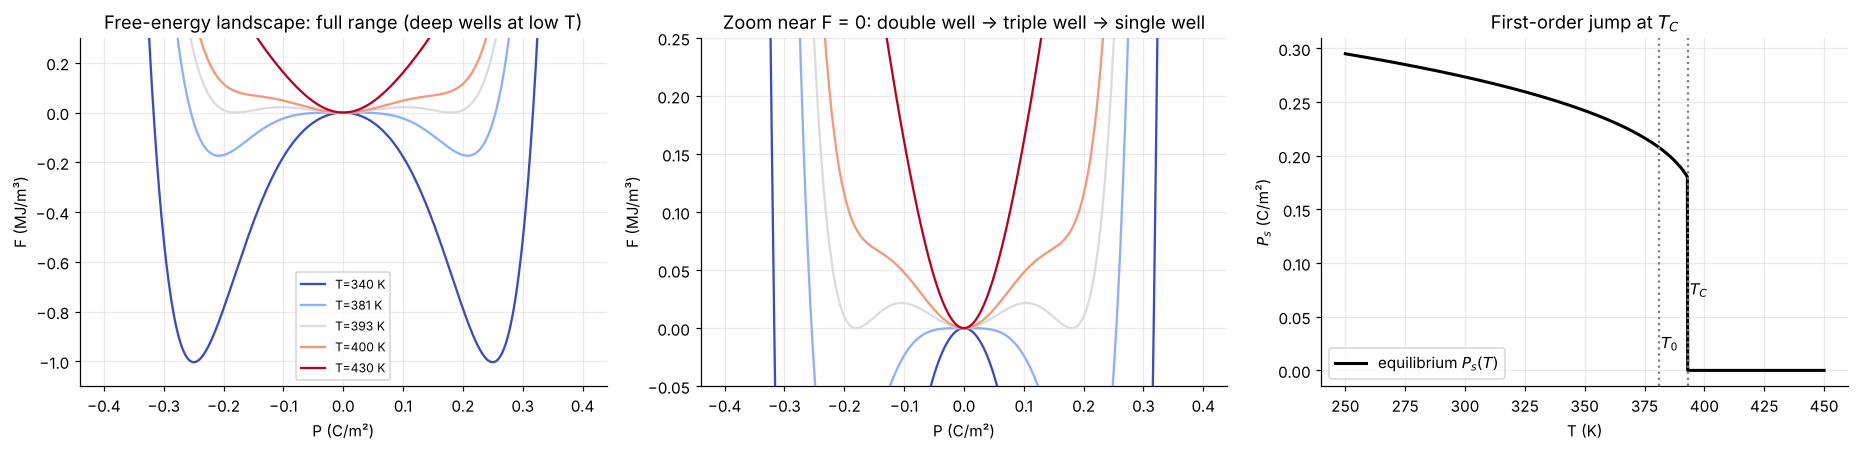

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
P = np.linspace(-0.4, 0.4, 600)
for T, col in zip([340, 381, 393, 400, 430], plt.cm.coolwarm(np.linspace(0, 1, 5))):
    for axx in ax[:2]: axx.plot(P, free_energy(P, T) / 1e6, color=col, label=f"T={T} K")
ax[0].set(xlabel="P (C/m²)", ylabel="F (MJ/m³)", ylim=(-1.1, 0.3), title="Free-energy landscape: full range (deep wells at low T)")
ax[1].set(xlabel="P (C/m²)", ylabel="F (MJ/m³)", ylim=(-0.05, 0.25), title="Zoom near F = 0: double well → triple well → single well")
ax[0].legend(fontsize=8)

Tg = np.linspace(250, 450, 1500)
ax[2].plot(Tg, ps_true(Tg), "k", lw=2, label="equilibrium $P_s(T)$")
for T_, n, yy in [(T0, "$T_0$", 0.02), (Tc, "$T_C$", 0.07)]:
    ax[2].axvline(T_, color="gray", ls=":"); ax[2].text(T_ + 1, yy, n)
ax[2].set(xlabel="T (K)", ylabel="$P_s$ (C/m²)", title="First-order jump at $T_C$")
ax[2].legend(); plt.tight_layout(); plt.show()

**What to notice.**

Below $T_C$ the ferroelectric wells are the global minima.

At $T_C$ they become degenerate with $P=0$.

Above $T_C$ the paraelectric state wins, although the ferroelectric well can survive as a *metastable* state a little above $T_C$.

A real heating/cooling experiment therefore shows **thermal hysteresis**. We will model the equilibrium (global-minimum) branch and flag history-dependence as something a $T$-only model can never know.

## 2. A synthetic experiment

We "measure" $P_s$ at **500 random temperatures** between 300 and 450 K, each with Gaussian noise $\sigma=0.006$ C/m² (about 2–3 % of the low-temperature value). 400 points go to training and 100 are held back as a **test set** that no model ever sees while fitting. The noise level is the **noise floor**: no model can have an RMSE below $\sigma$ on new noisy data.

train: 400 points   test: 100 points   noise floor (RMSE of a perfect model) = 0.006


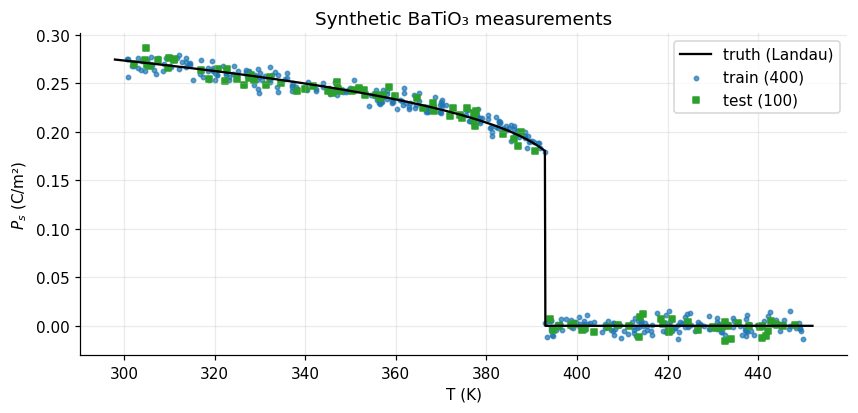

In [ ]:
SIGMA = 0.006
N = 500
T_all = rng.uniform(300, 450, N)
y_all = ps_true(T_all) + rng.normal(0, SIGMA, N)

idx = rng.permutation(N)
tr, te = idx[:400], idx[400:]
T_tr, y_tr, T_te, y_te = T_all[tr], y_all[tr], T_all[te], y_all[te]

print(f"train: {len(T_tr)} points   test: {len(T_te)} points   noise floor (RMSE of a perfect model) = {SIGMA}")

Tg = np.linspace(298, 452, 1500)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(Tg, ps_true(Tg), "k", lw=1.5, label="truth (Landau)")
ax.scatter(T_tr, y_tr, s=8, c=COL["train"], alpha=.7, label="train (400)")
ax.scatter(T_te, y_te, s=14, c=COL["test"], marker="s", label="test (100)")
ax.set(xlabel="T (K)", ylabel="$P_s$ (C/m²)", title="Synthetic BaTiO₃ measurements"); ax.legend(); plt.show()

## 3. Underfitting vs overfitting

We fit **polynomials of increasing degree** $d$ to $P_s(T)$. The degree is the model's *capacity*. For each $d$ we report three errors:

* **train** — error on the points the model was fitted to;
* **CV** — 5-fold cross-validation error inside the training set (what you would use to choose $d$);
* **test** — error on the held-out test set.

We do it twice: with a **small** training set (30 points, repeated on 30 random subsets and summarised by the median so that one lucky draw cannot mislead) and with the **full** one (400 points). What counts as "too flexible" depends on how much data you have.

30 points : best CV degree  4   median test RMSE 0.0327   (degree 15: 0.625)
400 points: best CV degree 15   test RMSE 0.0152   (degree 15: 0.0152)   noise floor 0.006


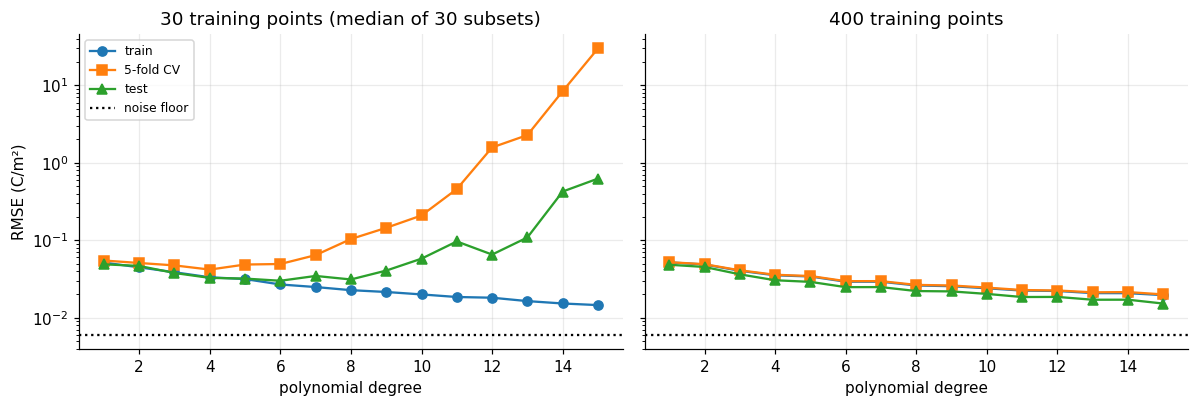

In [ ]:
X = lambda T: ((np.asarray(T, float) - 375) / 75)[:, None]      # scale temperature to about [-1, 1]

kf = KFold(5, shuffle=True, random_state=0)

sw_small, sw_full = sweep(30, 30), sweep(400, 1)
best_small, best_full = int(sw_small.cv.idxmin()), int(sw_full.cv.idxmin())
print(f"30 points : best CV degree {best_small:2d}   median test RMSE {sw_small.test[best_small]:.4f}   (degree 15: {sw_small.test[15]:.3f})")
print(f"400 points: best CV degree {best_full:2d}   test RMSE {sw_full.test[best_full]:.4f}   (degree 15: {sw_full.test[15]:.4f})   noise floor {SIGMA}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a_, sw, n_ in [(ax[0], sw_small, 30), (ax[1], sw_full, 400)]:
    a_.plot(sw.index, sw.train, "o-", label="train"); a_.plot(sw.index, sw.cv, "s-", label="5-fold CV"); a_.plot(sw.index, sw.test, "^-", label="test")
    a_.axhline(SIGMA, color="k", ls=":", label="noise floor"); a_.set_yscale("log")
    a_.set(xlabel="polynomial degree", title=f"{n_} training points" + (" (median of 30 subsets)" if n_ == 30 else ""))
ax[0].set_ylabel("RMSE (C/m²)"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

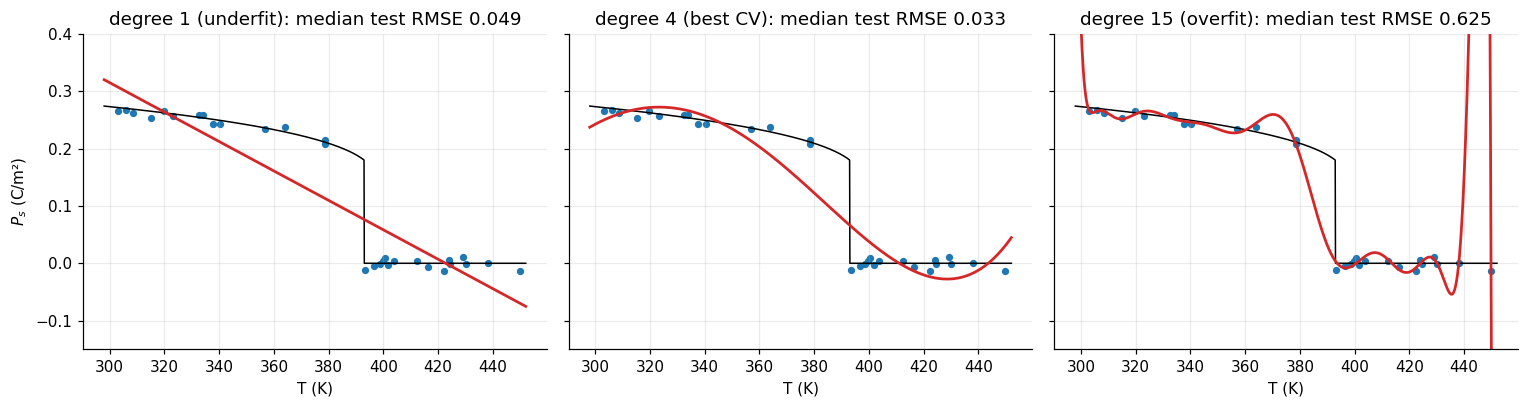

In [ ]:
sub = rng.choice(len(T_tr), 30, replace=False); T_sm, y_sm = T_tr[sub], y_tr[sub]       # one example 30-point training set
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a_, (d, lab) in zip(ax, [(1, "underfit"), (best_small, "best CV"), (15, "overfit")]):
    m = poly_model(d).fit(X(T_sm), y_sm)
    a_.scatter(T_sm, y_sm, s=14, c=COL["train"]); a_.plot(Tg, ps_true(Tg), "k", lw=1); a_.plot(Tg, m.predict(X(Tg)), COL["model"], lw=1.8)
    a_.set(ylim=(-0.15, 0.4), xlabel="T (K)", title=f"degree {d} ({lab}): median test RMSE {sw_small.test[d]:.3f}")
ax[0].set_ylabel("$P_s$ (C/m²)"); plt.tight_layout(); plt.show()

**Reading the plots** (compare the numbers printed above)

* **Underfitting (high bias):** a straight line has large train, CV *and* test error, all similar: the model cannot bend into a plateau followed by a cliff, and more data would not help.
* **Overfitting (high variance):** with only 30 points, train error keeps dropping with degree while CV and test error turn around and rise sharply, and the high-degree curve wiggles to chase noise (look at the ends).
* **More data moves the sweet spot.** With 400 points the same high degrees are no longer harmful and the best CV degree is larger. Overfitting is about capacity *relative to* the amount of data.
* **The floor is not the noise.** Even the best polynomial stays well above the noise floor: a smooth global polynomial cannot represent a discontinuity, so what remains is **bias**. Collecting more data does not remove it; a different model class (or physics) does.

---
## What we carry forward to notebook 2

* The **physics**: a first-order jump at $T_C$ = 393 K, a plateau at low $T$, and the noise floor $\sigma$ = 0.006.
* The two lessons: error splits into **bias** (wrong model class) and **variance** (too flexible for the data), and in-distribution test error says nothing about the situations we have not tested.

**Next:** real experiments are *not* 500 random points. Notebook 2 builds a sparse version of this dataset with holes in it (one hiding $T_C$) and a hidden-variable shift, then asks where six standard ML models break.